# Temporal Ensemble (fase)

SEED aplicado al registro desplazado 0–7 muestras (8 miembros) con la costura de 20 s / 10 s, y realineado al tiempo absoluto. Desplazar por segundos no sirve: dentro de la zona central de la ventana SEED casi no cambia su predicción. Su MI mide sensibilidad al corte temporal, no duda sobre los pesos. No entrena nada.


**Datos.** Evaluaciones 0, 1 y 2, cinco folds de test cada una (15 folds en total). Se leen los `test_predictions.npz` ya guardados: el notebook no entrena ni vuelve a inferir. Todo se calcula sobre los timesteps válidos.

**Cómo leer las tablas.** Cada tabla muestra *media ± desviación estándar* entre folds para cada evaluación (0, 1 y 2) y el promedio de las tres (los 15 folds juntos). Los gráficos tienen cuatro paneles con las mismas cuatro vistas.

**Definiciones que se repiten**

- *Cerca de eventos*: ±1 s alrededor de un huso real o predicho. Es donde ocurren los errores; el ~92% restante es fondo fácil que infla los AUROC.
- *Azar*: 0.5 para un AUROC; para un AUPRC, la proporción de positivos (tasa de error o proporción de FP/FN).
- *Aleatoria* = entropía esperada (ambigüedad de la señal); *epistémica* = MI (desacuerdo entre muestras del modelo); *total* = entropía predictiva = aleatoria + MI.
- *SEED H(p)*: la incertidumbre del SEED original sobre los mismos timesteps o eventos, como referencia.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import report

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

METHOD = 'Temporal Ensemble'
REFRESH = False  # True recalcula desde los NPZ (varios minutos)
results = report.method_results(METHOD, refresh=REFRESH)
metrics = results['metrics']

Temporal Ensemble: evaluación 0 lista
Temporal Ensemble: evaluación 1 lista
Temporal Ensemble: evaluación 2 lista


## 1. Detección y calibración

F1, precisión y recall por evento (IoU ≥ 0.2, métrica principal), AUROC/AUPRC de detección por timestep y calidad de la probabilidad (NLL, Brier y ECE de la clase positiva; menor es mejor).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
F1 evento (%),82.5 ± 0.69,82.99 ± 0.88,82.94 ± 0.91,82.81 ± 0.8
precisión (%),83.63 ± 6.4,84.64 ± 2.8,82.58 ± 3.6,83.62 ± 4.3
recall (%),82.18 ± 6.5,81.55 ± 2.9,83.49 ± 2.9,82.41 ± 4.2
AUROC detección,0.9915 ± 0.00098,0.9917 ± 0.0007,0.9915 ± 0.0003,0.9916 ± 0.00067
AUPRC detección,0.889 ± 0.0086,0.8908 ± 0.0046,0.8878 ± 0.009,0.8892 ± 0.0072
NLL,0.05207 ± 0.0039,0.05001 ± 0.0022,0.05057 ± 0.0043,0.05089 ± 0.0034
Brier,0.01512 ± 0.0011,0.01469 ± 0.00059,0.01505 ± 0.0014,0.01495 ± 0.001
ECE clase positiva,0.007272 ± 0.003,0.004628 ± 0.0019,0.005363 ± 0.0041,0.005755 ± 0.0031


F1 evento (%)  precisión (%)  recall (%)  AUROC detección  AUPRC detección     NLL   Brier  ECE clase positiva
evaluación fold                                                                                                                
0          0           82.3368        76.3113     89.3954           0.9916           0.8843  0.0535  0.0158              0.0114
           1           81.7431        83.8983     79.6959           0.9900           0.8777  0.0573  0.0163              0.0057
           2           83.2653        78.9338     88.0998           0.9919           0.8884  0.0509  0.0150              0.0077
           3           83.1818        86.5658     80.0525           0.9913           0.8987  0.0519  0.0152              0.0034
           4           81.9903        92.4390     73.6638           0.9926           0.8961  0.0468  0.0133              0.0081
1          0           82.9630        82.7331     83.1941           0.9922           0.8904  0.0471  0.0141              0.0050
           1           83.8923        85.1390     82.6816           0.9925           0.8977  0.0484  0.0144              0.0047
           2           81.8915        88.0925     76.5060           0.9917           0.8892  0.0503  0.0144              0.0065
           3           82.3743        80.9439     83.8561           0.9909           0.8850  0.0522  0.0155              0.0055
           4           83.8351        86.2726     81.5315           0.9911           0.8915  0.0521  0.0151              0.0014
2          0           82.5238        84.7737     80.3902           0.9912           0.8774  0.0483  0.0145              0.0028
           1           82.0762        76.7830     88.1533           0.9915           0.8968  0.0576  0.0173              0.0127
           2           82.2943        81.5217     83.0816           0.9919           0.8808  0.0474  0.0143              0.0038
           3           83.6763        85.3545     82.0628           0.9913           0.8872  0.0518  0.0151              0.0042
           4           84.1307        84.4910     83.7736           0.9918           0.8970  0.0478  0.0139              0.0033

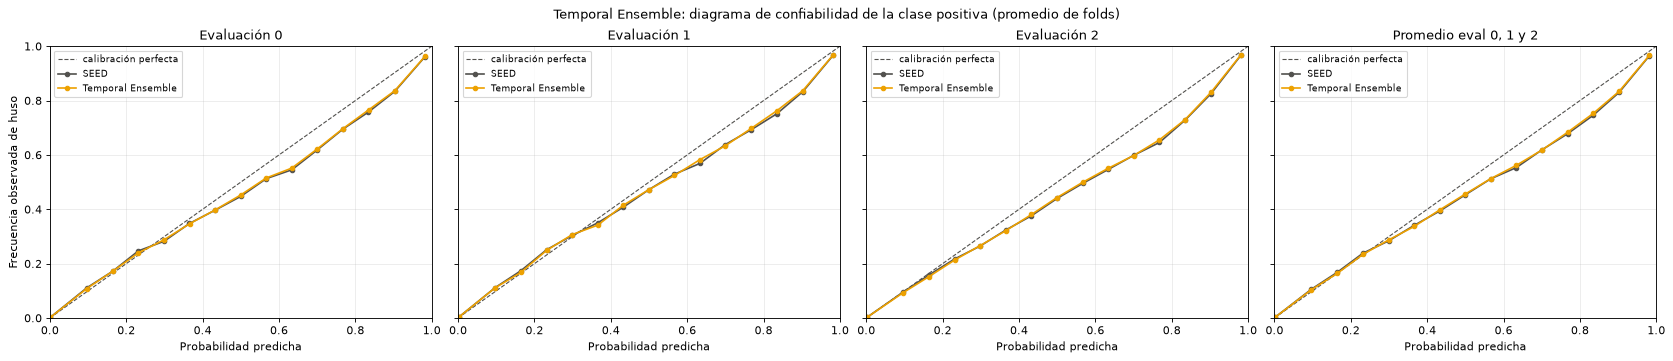

In [2]:
DETECTION = ['F1 evento (%)', 'precisión (%)', 'recall (%)', 'AUROC detección', 'AUPRC detección', 'NLL', 'Brier', 'ECE clase positiva']
display(report.by_evaluation(metrics, DETECTION))
display(metrics.set_index(['evaluación', 'fold'])[DETECTION].round(4))
show(report.plot_reliability(results, METHOD))

## 2. Curvas ROC

Curva promedio de los folds. *Detección*: huso vs fondo con la probabilidad. *Errores*: timesteps mal clasificados vs bien clasificados cerca de eventos, ordenados por cada medida de incertidumbre.

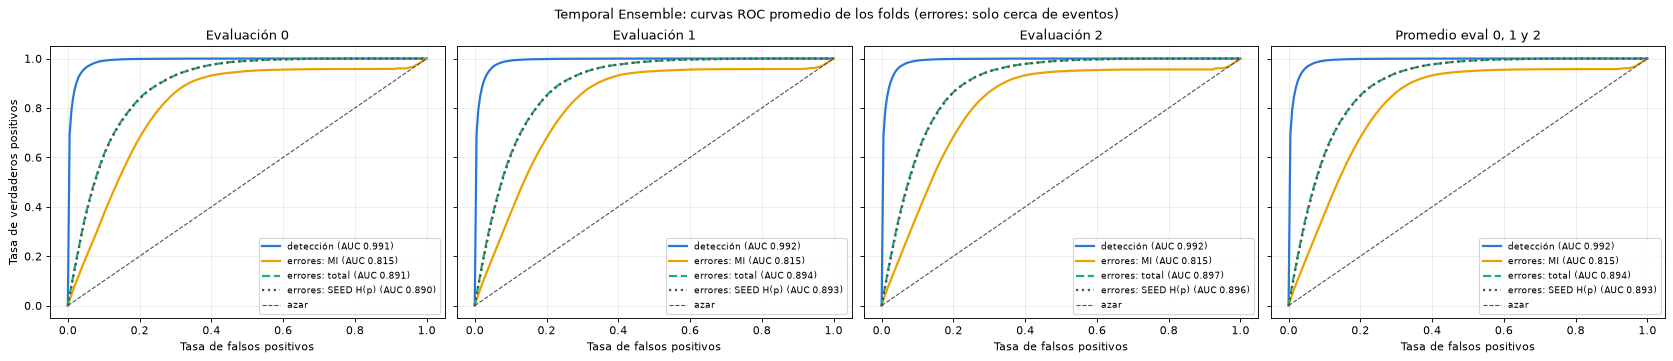

In [3]:
show(report.plot_roc(results, METHOD))

## 3. Descomposición de la incertidumbre

Entropía media en bits, en todo el registro y cerca de eventos, separada en aleatoria y epistémica (MI), con la incertidumbre de SEED como referencia.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
total (registro),0.06064 ± 0.0092,0.05927 ± 0.0089,0.06449 ± 0.006,0.06147 ± 0.0079
aleatoria (registro),0.06022 ± 0.0092,0.05885 ± 0.0089,0.06406 ± 0.006,0.06104 ± 0.0079
SEED H(p) (registro),0.06025 ± 0.0091,0.05881 ± 0.0089,0.06412 ± 0.006,0.06106 ± 0.0079
MI (registro),0.0004113 ± 6.4e-05,0.0004206 ± 4.7e-05,0.0004337 ± 7.1e-05,0.0004218 ± 5.8e-05
% epistémica (registro),0.6848 ± 0.11,0.7202 ± 0.11,0.6744 ± 0.11,0.6931 ± 0.1
total (cerca de eventos),0.2285 ± 0.01,0.2287 ± 0.026,0.2363 ± 0.008,0.2312 ± 0.016
aleatoria (cerca de eventos),0.2268 ± 0.01,0.2269 ± 0.026,0.2345 ± 0.0082,0.2294 ± 0.016
SEED H(p) (cerca de eventos),0.2267 ± 0.01,0.2267 ± 0.026,0.2346 ± 0.0082,0.2293 ± 0.016
MI (cerca de eventos),0.001777 ± 0.00018,0.001839 ± 0.00016,0.001819 ± 0.00018,0.001812 ± 0.00016
% epistémica (cerca de eventos),0.78 ± 0.098,0.8152 ± 0.13,0.7724 ± 0.1,0.7892 ± 0.11


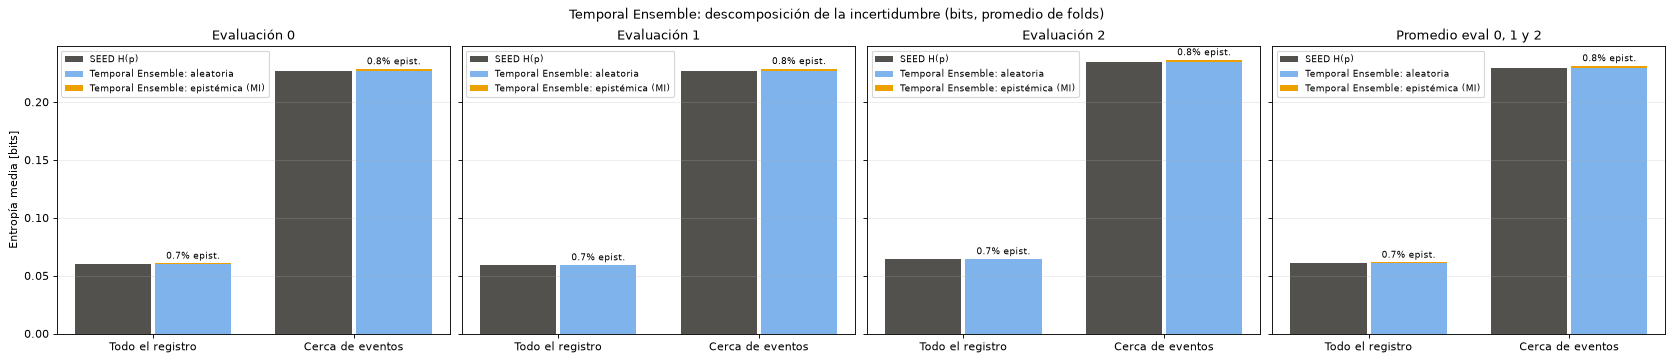

In [4]:
DECOMPOSITION = [c for c in metrics.columns if c.endswith('(registro)') or c.endswith('(cerca de eventos)')]
display(report.by_evaluation(metrics, DECOMPOSITION))
show(report.plot_decomposition(results, METHOD))

## 4. ¿La incertidumbre detecta los errores?

Errores por timestep cerca de eventos: AUROC y AUPRC de cada medida. El AUPRC se compara con la tasa de error (azar).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
AUROC errores: total,0.8913 ± 0.0045,0.8936 ± 0.0074,0.8966 ± 0.0016,0.8938 ± 0.0052
AUPRC errores: total,0.4126 ± 0.0078,0.412 ± 0.011,0.4165 ± 0.0048,0.4137 ± 0.008
AUROC errores: aleatoria,0.8915 ± 0.0045,0.8938 ± 0.0075,0.8968 ± 0.0016,0.894 ± 0.0053
AUPRC errores: aleatoria,0.4136 ± 0.0089,0.4129 ± 0.013,0.4171 ± 0.0058,0.4146 ± 0.0093
AUROC errores: SEED H(p),0.8904 ± 0.0044,0.8926 ± 0.0076,0.8955 ± 0.0016,0.8928 ± 0.0053
AUPRC errores: SEED H(p),0.4075 ± 0.0063,0.4063 ± 0.014,0.4103 ± 0.0068,0.408 ± 0.0092
AUROC errores: MI,0.8148 ± 0.0096,0.815 ± 0.013,0.8149 ± 0.0092,0.8149 ± 0.01
AUPRC errores: MI,0.284 ± 0.0056,0.2821 ± 0.018,0.2832 ± 0.0071,0.2831 ± 0.011
azar errores,0.1044 ± 0.0033,0.1027 ± 0.0047,0.1034 ± 0.0042,0.1035 ± 0.0039


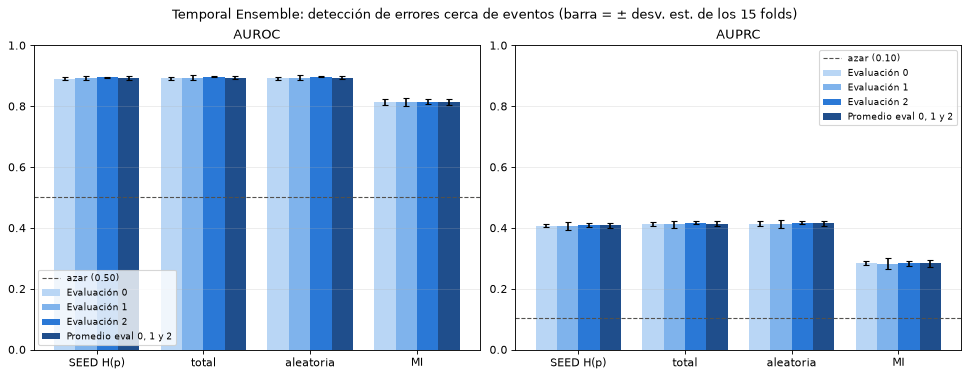

In [5]:
ERRORS = [c for c in metrics.columns if c.startswith('AUROC errores') or c.startswith('AUPRC errores')] + ['azar errores']
display(report.by_evaluation(metrics, ERRORS))
show(report.plot_error_detection(results, METHOD))

## 5. Dónde se concentra la incertidumbre

Entropía media por zona: bordes de los husos (±0.25 s del inicio o fin real), interior del huso y fondo.

Borde del huso
Interior del huso
Fondo


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,6.124 ± 0.34,6.124 ± 0.24,6.124 ± 0.36,6.124 ± 0.3
SEED H(p),0.4373 ± 0.015,0.4373 ± 0.033,0.4466 ± 0.014,0.4404 ± 0.021
aleatoria,0.4373 ± 0.015,0.4375 ± 0.033,0.4466 ± 0.014,0.4405 ± 0.021
MI,0.004377 ± 0.00041,0.004472 ± 0.00036,0.004423 ± 0.0004,0.004424 ± 0.00036


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,2.055 ± 0.25,2.055 ± 0.19,2.055 ± 0.2,2.055 ± 0.2
SEED H(p),0.2824 ± 0.076,0.2848 ± 0.057,0.2954 ± 0.066,0.2876 ± 0.062
aleatoria,0.2824 ± 0.075,0.2853 ± 0.056,0.2952 ± 0.066,0.2876 ± 0.062
MI,0.0009371 ± 0.0003,0.001034 ± 0.00024,0.0009894 ± 0.00023,0.0009867 ± 0.00024


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,91.82 ± 0.53,91.82 ± 0.36,91.82 ± 0.55,91.82 ± 0.45
SEED H(p),0.03029 ± 0.011,0.02841 ± 0.0057,0.0336 ± 0.006,0.03076 ± 0.0077
aleatoria,0.03026 ± 0.011,0.02842 ± 0.0057,0.03354 ± 0.0059,0.03074 ± 0.0077
MI,0.0001345 ± 3.3e-05,0.0001368 ± 3.3e-05,0.0001544 ± 3.7e-05,0.0001419 ± 3.3e-05


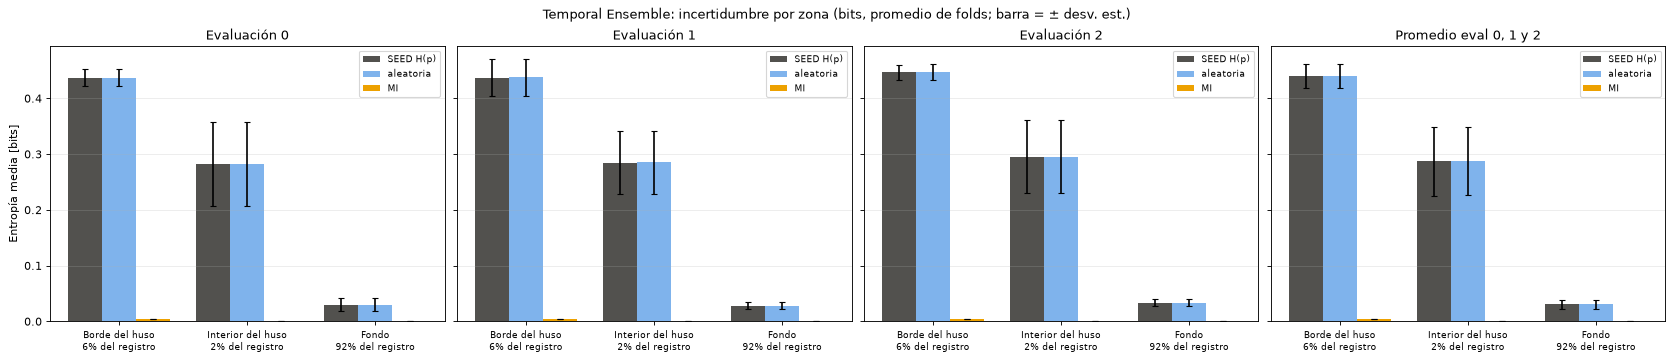

In [6]:
zones = results['zones']
for zone in ['Borde del huso', 'Interior del huso', 'Fondo']:
    print(zone)
    display(report.by_evaluation(zones[zones['zona'] == zone], [c for c in zones.columns if c not in ('evaluación', 'fold', 'zona')]))
show(report.plot_zones(results, METHOD))

## 6. Duración del evento vs incertidumbre

ρ es la correlación de Spearman entre la duración de cada evento predicho y su incertidumbre media (MI; para SEED, su entropía). ρ < 0: los eventos cortos son más inciertos.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
ρ duración-incertidumbre,-0.3166 ± 0.12,-0.4222 ± 0.097,-0.3872 ± 0.12,-0.3753 ± 0.11


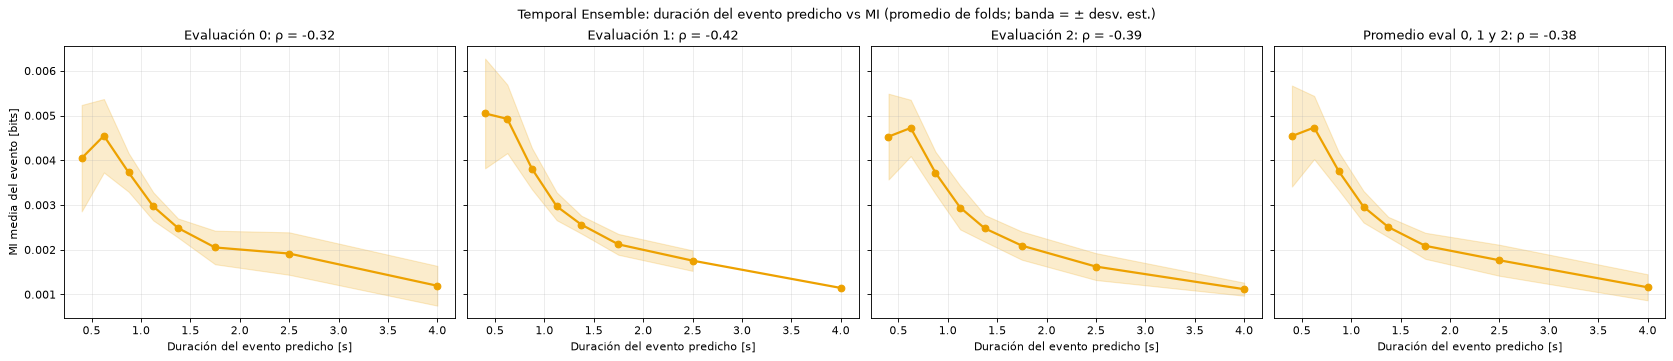

In [7]:
display(report.by_evaluation(metrics, ['ρ duración-incertidumbre']))
show(report.plot_duration(results, METHOD))

## 7. Aciertos, falsos positivos y falsos negativos

- **TP / FP (predicho)**: detecciones correctas y falsas, medidas en el tramo que el modelo predijo.
- **TP / FN (real)**: husos detectados y no detectados, medidos en el tramo real del huso (un FN no tiene tramo predicho). Los pares con IoU < 0.2 cuentan como FN, igual que en el F1.

Primero las medianas de cada medida, luego qué tan bien cada medida separa FP de TP y FN de TP (AUROC y AUPRC con su azar), y al final los gráficos de cajón en percentil dentro del fold, con la línea de azar en 0.5. Comparar la *probabilidad media* entre FN y TP es casi circular (un FN es justamente un tramo con probabilidad baja).

Medianas por tipo de evento
FP vs TP (tramo predicho)
FN vs TP (tramo real)


eval 0                                                                                           eval 1                                                                                           eval 2                      \
              probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std) probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std) probabilidad media incertidumbre total   
grupo                                                                                                                                                                                                                                                    
TP (predicho)             0.8782              0.4109    0.4075          0.0035                          0.0185             0.8794              0.4125    0.4091          0.0036                          0.0188             0.8783              0.4139   
FP (predicho)             0.6305              0.9296    0.9255          0.0031                          0.0261             0.6479              0.9092    0.9054          0.0035                          0.0277             0.6556              0.8998   
TP (real)                 0.8697              0.3767    0.3728          0.0029                          0.0167             0.8672              0.3791    0.3760          0.0031                          0.0171             0.8696              0.3811   
FN (real)                 0.1733              0.5990    0.5960          0.0017                          0.0153             0.1806              0.6313    0.6292          0.0017                          0.0161             0.1923              0.6241   

                                                                        promedio eval 0, 1 y 2                                                                                
              aleatoria epistémica (MI) dispersión entre muestras (std)     probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std)  
grupo                                                                                                                                                                         
TP (predicho)    0.4104          0.0036                          0.0188                 0.8787              0.4128    0.4091          0.0036                          0.0187  
FP (predicho)    0.8965          0.0035                          0.0273                 0.6461              0.9131    0.9084          0.0034                          0.0271  
TP (real)        0.3768          0.0030                          0.0167                 0.8686              0.3790    0.3755          0.0030                          0.0169  
FN (real)        0.6207          0.0017                          0.0163                 0.1824              0.6195    0.6167          0.0017                          0.0158

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1636 ± 0.064,0.1536 ± 0.028,0.1742 ± 0.036,0.1638 ± 0.043
AUROC probabilidad media,0.8538 ± 0.012,0.8464 ± 0.013,0.8443 ± 0.03,0.8482 ± 0.019
AUPRC probabilidad media,0.4597 ± 0.11,0.4463 ± 0.068,0.4781 ± 0.094,0.4614 ± 0.088
AUROC incertidumbre total,0.8555 ± 0.01,0.8504 ± 0.012,0.8492 ± 0.031,0.8517 ± 0.019
AUPRC incertidumbre total,0.4504 ± 0.13,0.449 ± 0.079,0.4776 ± 0.11,0.459 ± 0.1
AUROC aleatoria,0.8554 ± 0.01,0.8504 ± 0.012,0.8492 ± 0.031,0.8517 ± 0.019
AUPRC aleatoria,0.4489 ± 0.13,0.4447 ± 0.077,0.4745 ± 0.11,0.456 ± 0.1
AUROC epistémica (MI),0.4674 ± 0.047,0.4924 ± 0.06,0.4924 ± 0.047,0.4841 ± 0.049
AUPRC epistémica (MI),0.1759 ± 0.054,0.1832 ± 0.033,0.2009 ± 0.056,0.1867 ± 0.047
AUROC dispersión entre muestras (std),0.7508 ± 0.029,0.755 ± 0.023,0.7579 ± 0.044,0.7546 ± 0.031


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1778 ± 0.065,0.1845 ± 0.029,0.1651 ± 0.029,0.1758 ± 0.042
AUROC probabilidad media,0.9545 ± 0.023,0.9634 ± 0.015,0.9535 ± 0.033,0.9571 ± 0.024
AUPRC probabilidad media,0.9332 ± 0.043,0.947 ± 0.02,0.9283 ± 0.051,0.9362 ± 0.038
AUROC incertidumbre total,0.5941 ± 0.086,0.6242 ± 0.04,0.6278 ± 0.039,0.6154 ± 0.057
AUPRC incertidumbre total,0.2178 ± 0.041,0.2572 ± 0.026,0.2258 ± 0.018,0.2336 ± 0.033
AUROC aleatoria,0.5955 ± 0.086,0.6258 ± 0.04,0.6292 ± 0.039,0.6168 ± 0.057
AUPRC aleatoria,0.2188 ± 0.041,0.2586 ± 0.027,0.227 ± 0.018,0.2348 ± 0.033
AUROC epistémica (MI),0.3016 ± 0.026,0.3183 ± 0.06,0.3165 ± 0.075,0.3121 ± 0.054
AUPRC epistémica (MI),0.1288 ± 0.05,0.1361 ± 0.016,0.1218 ± 0.02,0.1289 ± 0.03
AUROC dispersión entre muestras (std),0.45 ± 0.047,0.4708 ± 0.063,0.4658 ± 0.085,0.4622 ± 0.063


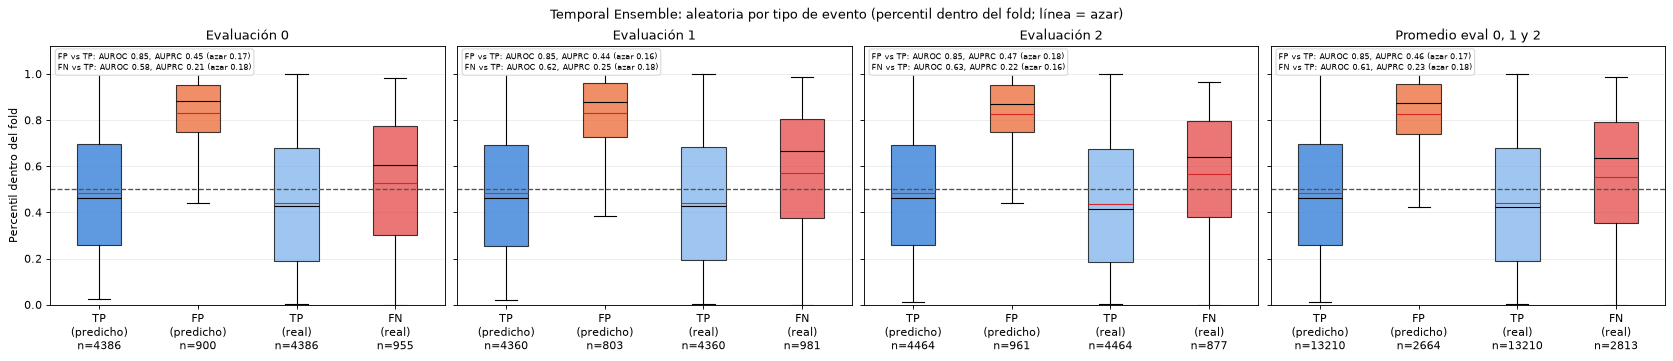

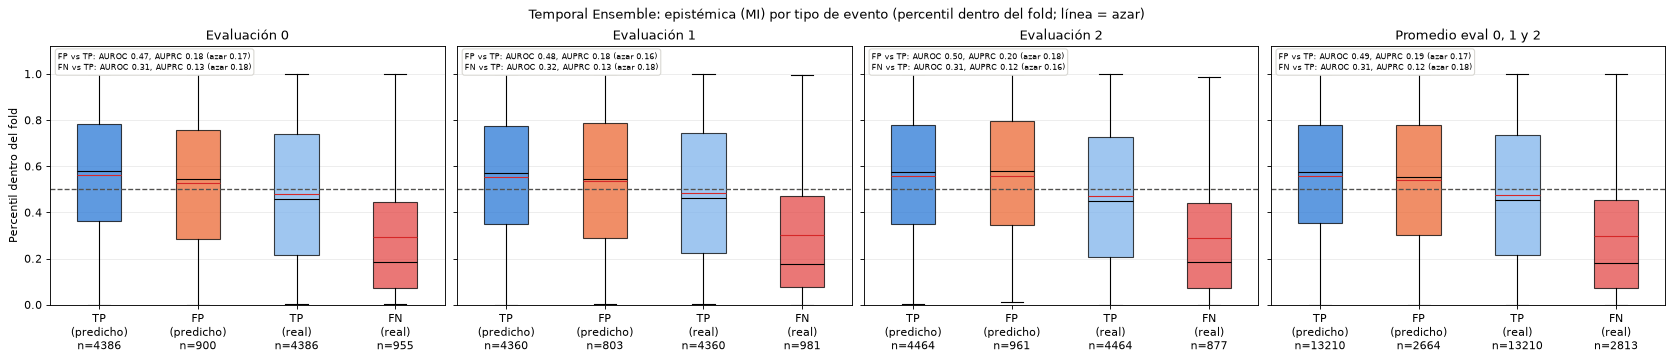

In [8]:
events = results['events']
print('Medianas por tipo de evento')
display(report.event_medians(events))
print('FP vs TP (tramo predicho)')
display(report.event_separation(events, 'TP (predicho)', 'FP (predicho)'))
print('FN vs TP (tramo real)')
display(report.event_separation(events, 'TP (real)', 'FN (real)'))
for figure in report.plot_event_boxes(results, METHOD):
    show(figure)

## 8. Derivar a revisión las detecciones más inciertas

Si se manda a revisión el x% de detecciones con más incertidumbre, ¿qué precisión tiene lo que se acepta automáticamente y qué parte de los falsos positivos se captura?

eval 0
eval 1
eval 2
promedio eval 0, 1 y 2


precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          83.6            83.6                83.6                0.0             0.0                 0.0
5.0                          85.4            84.0                85.5               16.1             8.0                16.1
10.0                         87.2            83.8                87.2               30.3            11.9                29.9
20.0                         91.2            83.4                91.2               58.4            19.9                58.4
30.0                         94.3            83.1                94.2               77.4            28.3                76.5

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          84.6            84.6                84.6                0.0             0.0                 0.0
5.0                          86.3            85.2                86.5               15.4             8.7                16.6
10.0                         88.5            85.3                88.6               32.7            14.5                33.1
20.0                         91.8            85.1                91.9               57.4            23.1                58.0
30.0                         94.4            84.7                94.4               74.3            31.0                74.6

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          82.6            82.6                82.6                0.0             0.0                 0.0
5.0                          84.5            83.0                84.5               15.5             7.3                15.5
10.0                         86.4            83.1                86.3               29.8            12.4                28.9
20.0                         90.1            83.0                90.1               54.5            21.5                54.5
30.0                         93.7            82.6                93.8               74.8            29.5                74.9

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          83.6            83.6                83.6                0.0             0.0                 0.0
5.0                          85.4            84.1                85.5               15.7             8.0                16.1
10.0                         87.4            84.1                87.3               30.9            12.9                30.6
20.0                         91.0            83.8                91.1               56.8            21.5                57.0
30.0                         94.1            83.4                94.1               75.5            29.6                75.3

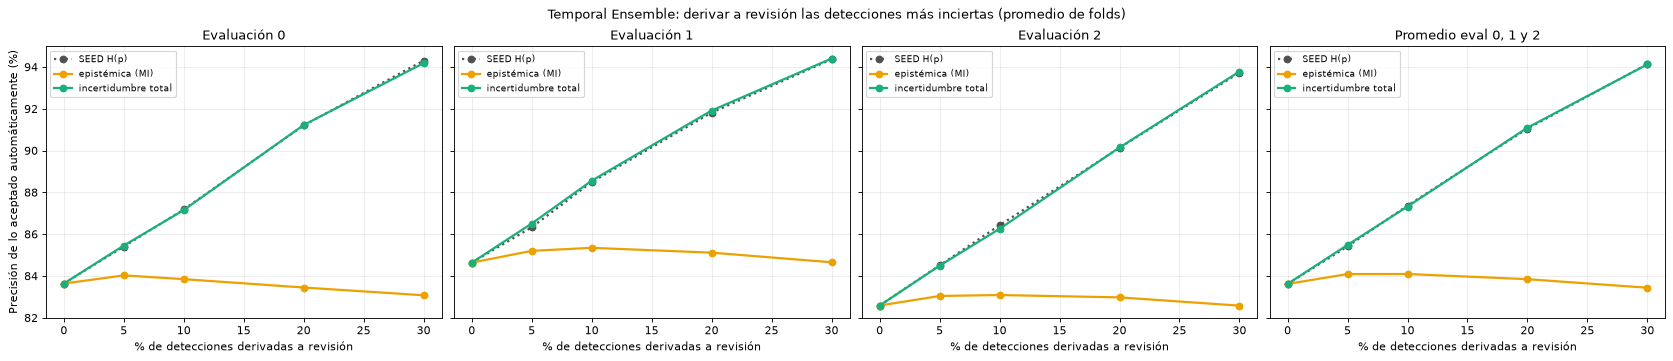

In [9]:
deferral = results['deferral'].dropna(subset=['% derivado'])
for label, part in [(f'eval {e}', deferral[deferral['evaluación'] == e]) for e in report.EVALUATIONS] + [(report.MEAN_SCOPE.lower(), deferral)]:
    print(label)
    display(part.groupby(['medida', '% derivado'])[['precisión aceptado (%)', '% de FP capturados']].mean().round(1).unstack('medida'))
show(report.plot_deferral(results, METHOD))

## 9. Descartar automáticamente las detecciones más inciertas

Sin revisión humana: se eliminan las detecciones con mayor incertidumbre (MI; para SEED, entropía). Los aciertos eliminados pasan a ser falsos negativos. Para que el F1 suba, más de ~58% de lo descartado debe ser FP (con F1 ≈ 83%, el equilibrio es 1 − F1/2).

FP descartados  TP descartados  % FP en lo descartado  cambio F1 (puntos)
medida              % descartado                                                                           
SEED H(p)           0.5                     2.47            2.73                  45.81               -0.06
                    1.0                     5.33            5.33                  49.15               -0.09
                    2.0                    11.07            9.93                  51.55               -0.13
                    5.0                    27.27           25.67                  50.46               -0.39
                    10.0                   54.13           51.53                  50.16               -0.82
                    20.0                   99.87          111.80                  46.09               -2.63
epistémica (MI)     0.5                     2.20            3.00                  41.03               -0.08
                    1.0                     4.27            6.40                  39.31               -0.19
                    2.0                     7.07           13.93                  32.78               -0.51
                    5.0                    13.67           39.27                  25.32               -1.68
                    10.0                   22.27           83.40                  20.65               -3.94
                    20.0                   37.47          174.20                  17.28               -9.07
incertidumbre total 0.5                     2.73            2.47                  51.54               -0.03
                    1.0                     5.73            4.93                  52.90               -0.05
                    2.0                    11.40            9.60                  52.77               -0.10
                    5.0                    28.00           24.93                  51.83               -0.32
                    10.0                   53.73           51.93                  49.76               -0.86
                    20.0                  100.27          111.40                  46.27               -2.59

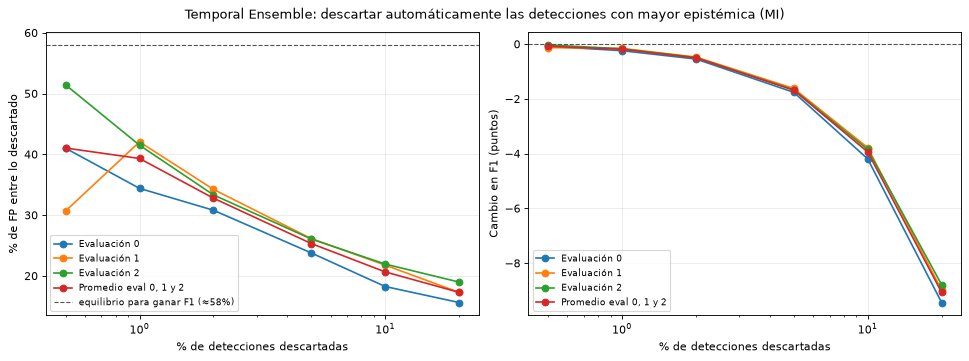

In [10]:
rejection = results['deferral'].dropna(subset=['% descartado'])
display(rejection.groupby(['medida', '% descartado'])[['FP descartados', 'TP descartados', '% FP en lo descartado', 'cambio F1 (puntos)']].mean().round(2))
show(report.plot_rejection(results, METHOD))

## Hallazgos

Cifras como eval 0 / eval 1 / eval 2 / promedio de las tres (15 folds de test); un solo número es el promedio.

1. **SEED es casi insensible al corte temporal:** la parte epistémica (desacuerdo entre los 8 desplazamientos) es solo 0.8% del total, la menor de todos los métodos. Desplazar la ventana por segundos ni siquiera produce variación (diagnóstico en `docs/temporal_ensemble.md`).
2. **La detección y la calibración no cambian:** F1 82.5% / 83.0% / 82.9% / 82.8%, ECE igual a SEED.
3. **Su MI detecta algo de los errores por timestep** (AUROC 0.815 en las tres evaluaciones, AUPRC 0.28), pero bastante menos que la propia incertidumbre de SEED (0.894).
4. **Para falsos positivos queda en el azar** (AUROC 0.47 / 0.49 / 0.49 / 0.48; AUPRC 0.19 con azar 0.16), igual que la implementación anterior (0.46). Para falsos negativos se invierte (0.31).
5. **La razón:** desplazar unas muestras equivale a mover la predicción unos milisegundos, así que los miembros discrepan donde la probabilidad cambia rápido: la MI mide qué tan nítido es el borde. Los aciertos tienen bordes más nítidos que los FP, por eso la MI no marca los FP.
6. **Descartar por MI hace caer el F1 hasta 9 puntos** (solo 17–41% de FP entre lo descartado).

**Conclusión.** El Temporal Ensemble no aporta una incertidumbre útil sobre SEED. Es un resultado del método aplicado a este modelo, no un error de implementación.